<a href="https://colab.research.google.com/github/Asfia-Arpi/Thesis-Codes/blob/main/ResNet50%20%2B%20EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset_path = '/content/drive/MyDrive/Thesis Arpi37/Dataset_new'

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt
import numpy as np
import os, time
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_score, recall_score, f1_score
)


In [ ]:
img_size = (224, 224)
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_image(image, label):
    # image is already tf.float32 and in [0, 1] range from image_dataset_from_directory
    image = (image - 0.5) / 0.5  # Scale [0, 1] to [-1, 1]
    label = tf.cast(label, tf.float32) # Explicitly cast label to float32
    return image, label

train_ds = train_ds.map(preprocess_image).cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.map(preprocess_image).cache().prefetch(AUTOTUNE)

Found 7902 files belonging to 2 classes.
Using 6322 files for training.
Found 7902 files belonging to 2 classes.
Using 1580 files for validation.


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

🔧 FINE-TUNING INFORMATION

🟦 ResNet50 Total Layers: 175
   ➤ Trainable Layers: 30

🟩 EfficientNetB0 Total Layers: 238
   ➤ Trainable Layers: 30



📘 MODEL SUMMARY =======================
Model: "ResNet50_EfficientNetB0_Ensemble_FT"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ input_layer_2[0]… │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ input_layer_2[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────

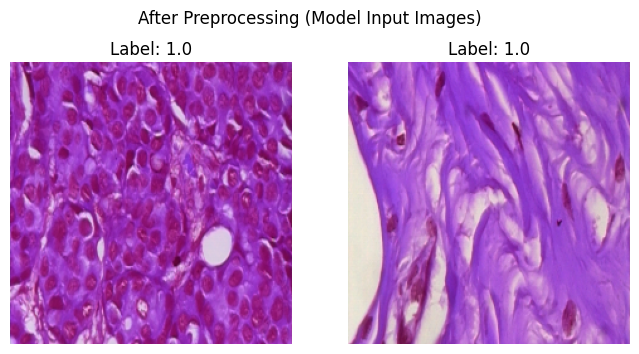

In [ ]:
# ======================================================
# ✅ MODEL: ResNet50 + EfficientNetB0 (Ensemble + Fine Tuning)
# ======================================================

import tensorflow as tf
from tensorflow.keras import layers, metrics, Model
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
import matplotlib.pyplot as plt
import io
import numpy as np


# ------------------------------------------------------
# 🔒 Freeze utility
# ------------------------------------------------------
def freeze_until(layer_list, train_from):
    total = len(layer_list)

    if train_from >= 0:
        start = train_from
    else:
        start = total + train_from

    for i, layer in enumerate(layer_list):
        layer.trainable = (i >= start)

    return start, total


# ------------------------------------------------------
# 🖼️ Show 2 Preprocessed Images from Dataset
# ------------------------------------------------------
def show_preprocessed_images(dataset, preprocess_fn):
    for images, labels in dataset.take(1):

        images = images[:2]
        labels = labels[:2]

        images_pre = preprocess_fn(images)

        plt.figure(figsize=(8, 4))

        for i in range(2):
            plt.subplot(1, 2, i + 1)

            img = images_pre[i].numpy()

            # Normalize ONLY for visualization
            img = (img - img.min()) / (img.max() - img.min())

            plt.imshow(img)
            plt.title(f"Label: {labels[i].numpy()}")
            plt.axis("off")

        plt.suptitle("After Preprocessing (Model Input Images)")
        plt.show()

        break


# ------------------------------------------------------
# 🧠 Build Ensemble Model (Fine-tuned)
# ------------------------------------------------------
def build_ensemble_resnet_efficientnet_finetune(
        dropout_rate=0.3,
        learning_rate=0.0001,
        resnet_train_from=-30,
        efficientnet_train_from=-30
):

    # Base Models
    res_base = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3)
    )

    eff_base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(224, 224, 3)
    )

    print("\n==========================")
    print("🔧 FINE-TUNING INFORMATION")
    print("==========================")

    res_start, res_total = freeze_until(res_base.layers, resnet_train_from)
    eff_start, eff_total = freeze_until(eff_base.layers, efficientnet_train_from)

    print(f"\n🟦 ResNet50 Total Layers: {res_total}")
    print(f"   ➤ Trainable Layers: {res_total - res_start}")

    print(f"\n🟩 EfficientNetB0 Total Layers: {eff_total}")
    print(f"   ➤ Trainable Layers: {eff_total - eff_start}")

    # Input
    inputs = tf.keras.Input(shape=(224, 224, 3))

    # Branch 1
    x1 = res_base(inputs, training=True)
    x1 = layers.GlobalAveragePooling2D()(x1)

    # Branch 2
    x2 = eff_base(inputs, training=True)
    x2 = layers.GlobalAveragePooling2D()(x2)

    # Combine
    combined = layers.concatenate([x1, x2])
    combined = layers.Dropout(dropout_rate)(combined)
    outputs = layers.Dense(1, activation="sigmoid")(combined)

    model = Model(inputs, outputs, name="ResNet50_EfficientNetB0_Ensemble_FT")

    optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            metrics.Precision(name="precision"),
            metrics.Recall(name="recall")
        ]
    )

    # Summary
    stream = io.StringIO()
    model.summary(print_fn=lambda x: stream.write(x + "\n"))
    print("\n📘 MODEL SUMMARY =======================")
    print(stream.getvalue())
    print("========================================")

    total_params = model.count_params()
    trainable_params = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)

    print("\n🔍 PARAMETER INFORMATION:")
    print(f"  ➤ Total Parameters:     {total_params:,}")
    print(f"  ➤ Trainable Parameters: {trainable_params:,}")

    return model


# ------------------------------------------------------
# 🚀 BUILD MODEL
# ------------------------------------------------------
model = build_ensemble_resnet_efficientnet_finetune(
    dropout_rate=0.3,
    learning_rate=1e-4,
    resnet_train_from=-30,
    efficientnet_train_from=-30
)

print("\n✅ Ensemble Model Ready!")


# ------------------------------------------------------
# 👀 VISUALIZE PREPROCESSED DATA
# ------------------------------------------------------
# ⚠️ train_ds must be defined before this
show_preprocessed_images(
    dataset=train_ds,
    preprocess_fn=resnet_preprocess
)


In [ ]:
# =============================
# ✅ TRAINING (ResNet50 + EfficientNetB0 Ensemble — Fine Tuning)
# =============================
import time

epochs = 30
print(f"\n🚀 Training ResNet50 + EfficientNetB0 Ensemble (Fine Tuning) for {epochs} epochs ...")

# NOTE:
# model = build_ensemble_resnet_efficientnet_finetune(...)
# fine-tuning enabled model

start = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)
end = time.time()

# =============================
# ✅ METRIC CALCULATIONS
# =============================

precision = history.history.get('precision', [0])[-1]
recall = history.history.get('recall', [0])[-1]
f1 = 2 * (precision * recall) / (precision + recall + 1e-7)

val_precision = history.history.get('val_precision', [0])[-1]
val_recall = history.history.get('val_recall', [0])[-1]
val_f1 = 2 * (val_precision * val_recall) / (val_precision + val_recall + 1e-7)

training_time = end - start

# =============================
# ✅ DISPLAY RESULTS
# =============================
print("\n📊 FINAL TRAINING RESULTS (ResNet50 + EfficientNetB0 Ensemble — Fine Tuning)")
print("==============================================================")
print(f"🕒 Training Time:           {training_time:.2f} seconds")
print(f"✅ Accuracy:                {history.history['accuracy'][-1]:.4f}")
print(f"✅ Precision:               {precision:.4f}")
print(f"✅ Recall:                  {recall:.4f}")
print(f"✅ F1 Score:                {f1:.4f}")
print("--------------------------------------------------------------")
print(f"🏁 Validation Accuracy:     {history.history['val_accuracy'][-1]:.4f}")
print(f"🏁 Validation Precision:    {val_precision:.4f}")
print(f"🏁 Validation Recall:       {val_recall:.4f}")
print(f"🏁 Validation F1 Score:     {val_f1:.4f}")
print("==============================================================")



🚀 Training ResNet50 + EfficientNetB0 Ensemble (Fine Tuning) for 30 epochs ...
Epoch 1/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 2487s 12s/step - accuracy: 0.8123 - loss: 0.4126 - precision: 0.8498 - recall: 0.8769 - val_accuracy: 0.8791 - val_loss: 0.3048 - val_precision: 0.9342 - val_recall: 0.8848
Epoch 2/30
104/198 ━━━━━━━━━━━━━━━━━━━━ 16:16 10s/step - accuracy: 0.9335 - loss: 0.1664 - precision: 0.9403 - recall: 0.9632

In [ ]:
training_time = end - start

# Print formatted runtime
print(f"\n⏱️ Total Training Time: {training_time // 60:.0f} minutes {training_time % 60:.2f} seconds")

In [ ]:
model.save("best_model.keras")
print("✅ Model saved as best_model.keras")


In [ ]:
loaded_model = tf.keras.models.load_model("best_model.keras")
print("✅ Model loaded successfully!")


In [ ]:
def get_last_conv_layer(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
        if isinstance(layer, tf.keras.Model):
            for sub_layer in reversed(layer.layers):
                if isinstance(sub_layer, tf.keras.layers.Conv2D):
                    return sub_layer.name
    raise ValueError("❌ No Conv2D layer found")


In [ ]:
def load_image_for_gradcam(img_path, img_size=(224,224)):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=img_size)
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = img_array / 255.0           # [0,1]
    model_input = (img_array - 0.5) / 0.5   # [-1,1]  (same as training)
    return img_array, np.expand_dims(model_input, axis=0)


In [ ]:
def gradcam_plus_plus(model, img_tensor, layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    first = grads
    second = grads ** 2
    third = grads ** 3

    global_sum = tf.reduce_sum(conv_outputs, axis=(1, 2), keepdims=True)

    alpha_num = second
    alpha_denom = 2 * second + third * global_sum
    alpha_denom = tf.where(alpha_denom != 0.0, alpha_denom, tf.ones_like(alpha_denom))

    alphas = alpha_num / alpha_denom
    weights = tf.reduce_sum(alphas * tf.nn.relu(first), axis=(1, 2))

    cam = tf.reduce_sum(weights[:, tf.newaxis, tf.newaxis, :] * conv_outputs, axis=-1)

    cam = tf.nn.relu(cam)
    cam = cam[0].numpy()
    cam = (cam - cam.min()) / (cam.max() + 1e-8)

    return cam


In [ ]:
def show_gradcam_results(img_path, model):
    original_img, input_tensor = load_image_for_gradcam(img_path)

    last_conv_layer = get_last_conv_layer(model)
    print(f"✅ Using last conv layer: {last_conv_layer}")

    cam = gradcam_plus_plus(model, input_tensor, last_conv_layer)

    cam = cv2.resize(cam, (224,224))
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    overlay = heatmap * 0.4 + (original_img * 255)
    overlay = overlay / 255.0

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(original_img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(heatmap)
    plt.title("Grad-CAM++ Heatmap")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(overlay)
    plt.title("Overlay")
    plt.axis("off")

    plt.show()


In [ ]:
import cv2

img_path = "/content/drive/MyDrive/Thesis Arpi37/Dataset_new/Malignant/SOB_M_DC-14-10926-100-001.png"

show_gradcam_results(img_path, model)


📊 Generating all graphs from existing training history...



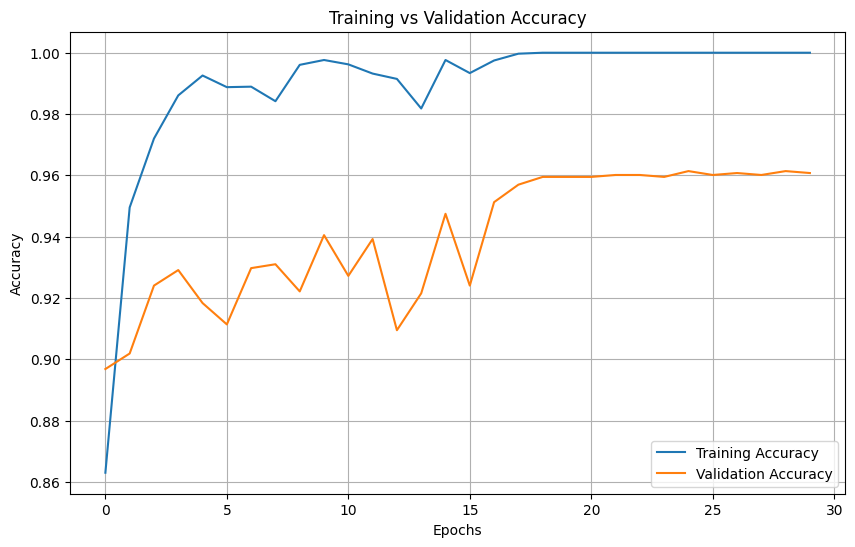

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/accuracy_curve.png


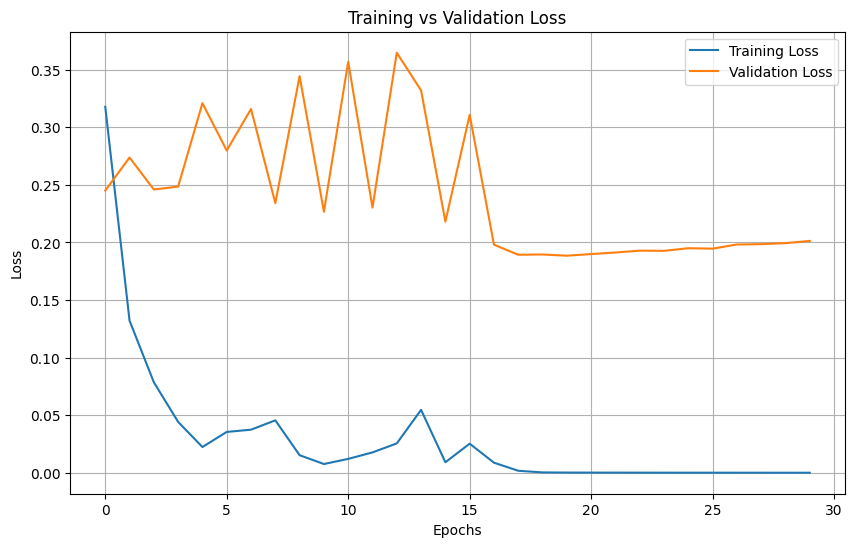

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/loss_curve.png


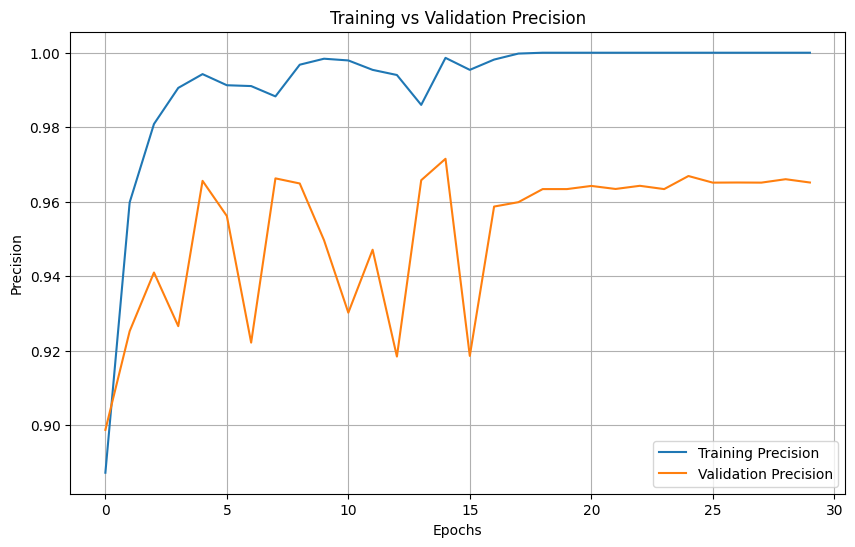

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/precision_curve.png


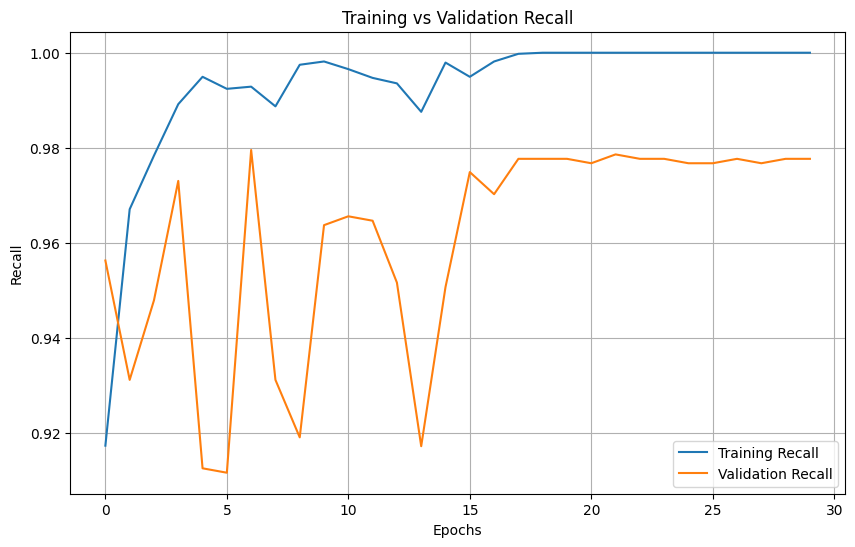

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/recall_curve.png


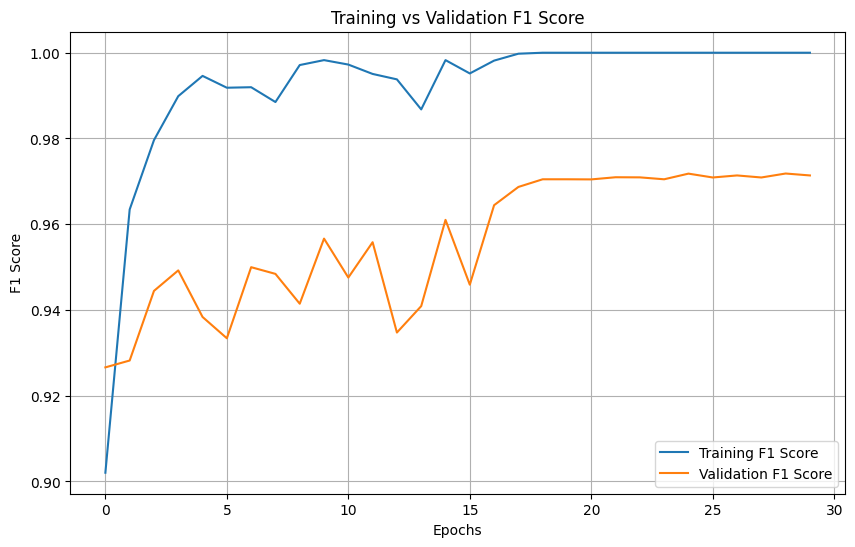

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/f1_curve.png
🔹 Generating AUC-ROC Curve ...
50/50 ━━━━━━━━━━━━━━━━━━━━ 34s 399ms/step


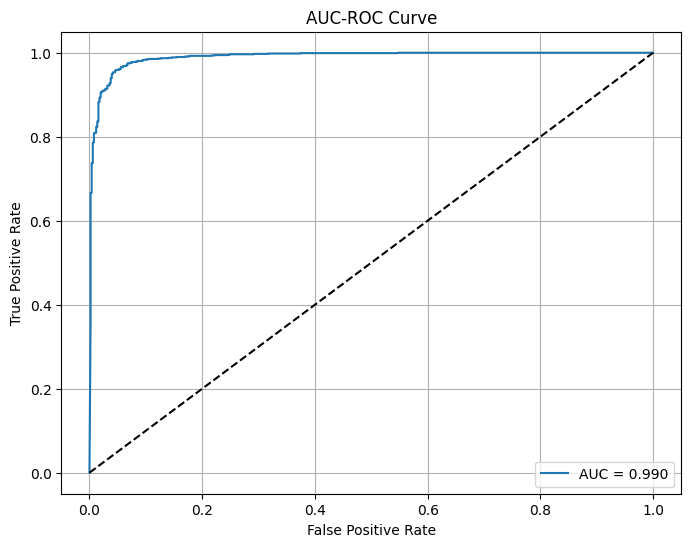

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/roc_curve.png
🔹 Generating Confusion Matrix ...


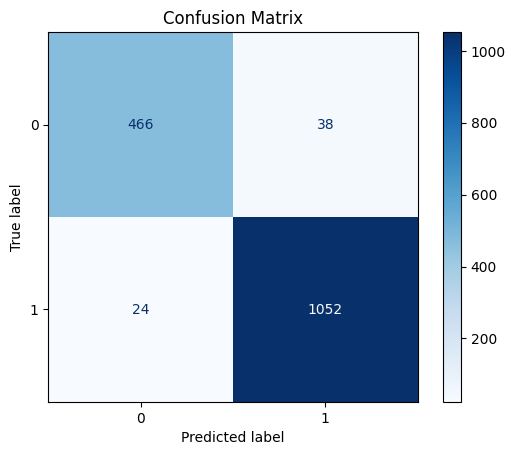

✅ Saved: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi/confusion_matrix.png

✅ All graphs displayed & saved successfully!
📂 Saved in folder: /content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi


In [ ]:
# ✅ VISUALIZATION AFTER TRAINING (FIXED & FINAL)
# ===============================================
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import os

print("📊 Generating all graphs from existing training history...\n")

# ✅ Folder path where all figures will be saved
save_dir = '/content/drive/MyDrive/Thesis Arpi37/Result/Ensemble3_Finetuning_XAi'

# Create the folder if it doesn’t exist
os.makedirs(save_dir, exist_ok=True)

# ✅ Helper function to save and show plots
def save_and_show_plot(filename):
    path = os.path.join(save_dir, filename)
    plt.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"✅ Saved: {path}")

# 1️⃣ Training vs Validation Accuracy
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
save_and_show_plot('accuracy_curve.png')

# 2️⃣ Training vs Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
save_and_show_plot('loss_curve.png')

# 3️⃣ Training vs Validation Precision
plt.figure(figsize=(10, 6))
plt.plot(history.history['precision'], label='Training Precision')
plt.plot(history.history['val_precision'], label='Validation Precision')
plt.title('Training vs Validation Precision')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()
plt.grid(True)
save_and_show_plot('precision_curve.png')

# 4️⃣ Training vs Validation Recall
plt.figure(figsize=(10, 6))
plt.plot(history.history['recall'], label='Training Recall')
plt.plot(history.history['val_recall'], label='Validation Recall')
plt.title('Training vs Validation Recall')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()
plt.grid(True)
save_and_show_plot('recall_curve.png')

# 5️⃣ Training vs Validation F1 Score
f1 = [2 * (p * r) / (p + r + 1e-7) for p, r in zip(history.history['precision'], history.history['recall'])]
val_f1 = [2 * (p * r) / (p + r + 1e-7) for p, r in zip(history.history['val_precision'], history.history['val_recall'])]
plt.figure(figsize=(10, 6))
plt.plot(f1, label='Training F1 Score')
plt.plot(val_f1, label='Validation F1 Score')
plt.title('Training vs Validation F1 Score')
plt.xlabel('Epochs')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)
save_and_show_plot('f1_curve.png')

# 6️⃣ AUC-ROC Curve
print("🔹 Generating AUC-ROC Curve ...")
y_true = np.concatenate([y for x, y in val_ds], axis=0)
y_pred_prob = model.predict(val_ds).ravel()
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('AUC-ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
save_and_show_plot('roc_curve.png')

# 7️⃣ Confusion Matrix
print("🔹 Generating Confusion Matrix ...")
y_pred = (y_pred_prob > 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
save_and_show_plot('confusion_matrix.png')

print("\n✅ All graphs displayed & saved successfully!")
print(f"📂 Saved in folder: {save_dir}")
